# Wie genau erkennt das CNN Straßenobjekte auf neuen Fahrten?

Wir vergleichen zwei SSDLite-Detektoren auf KITTI. Die Referenz lernt aus 40 Bildern. Unser erweitertes Modell nutzt 768 Bilder und vortrainierte Bildmerkmale. Beide müssen auf denselben zurückgehaltenen Fahrten für jedes Objekt die Klasse und eine passende Box vorhersagen.

## Vom SSD-Verfahren zum KITTI-Modell

MobileNetV3 extrahiert Bildmerkmale auf mehreren Auflösungen. Der SSDLite-Kopf bewertet an jedem Ort vorgegebene Rechtecke (Anker) und lernt, deren Lage und Größe zu korrigieren. Von Liu et al. übernehmen wir auch die Idee, Bild und Boxen gemeinsam zu spiegeln und die Bildfarben beim Training leicht zu variieren. [Liu et al., *SSD*, ECCV 2016](https://doi.org/10.1007/978-3-319-46448-0_2)

Entfernte Fahrzeuge belegen im Straßenbild oft nur wenige Pixel. Ren et al. verkleinerten für ihren KITTI-Detektor die kleinste Ankerskala auf 0,066. Wir übernehmen diesen Wert und verarbeiten die breiten Kamerabilder mit 640 × 192 Pixeln. Die folgende Verteilung zeigt, welche Objektgrößen in unserem Training vorkommen. [Ren et al., CVPR 2017, Abschnitt 4](https://arxiv.org/pdf/1704.05776)

## Warum wir nach Fahrten aufteilen

Benachbarte Frames können dieselben Autos vor fast identischem Hintergrund zeigen. Deshalb gehört jede Fahrt vollständig zu einer Gruppe. Die 768 Trainingsbilder liefern die Gewichtsänderungen, 192 Validierungsbilder entscheiden über die Epoche, 256 weitere Bilder dienen dem Abschlusstest. Die feste Bildliste mit Seed 42 nutzt die Fahrtzuordnung aus dem KITTI-Devkit. [KITTI Object Detection](https://www.cvlibs.net/datasets/kitti/eval_object.php)

In [1]:
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image
import torch
from torchvision.models import MobileNet_V3_Large_Weights
from torchvision.models.detection import ssdlite320_mobilenet_v3_large
from torchvision.models.detection.anchor_utils import DefaultBoxGenerator

from src.kitti import CLASSES, ROOT, annotations, image_path
from src.kitti_cnn import SIZE, Scenes, batches, evaluate

seed = 42
torch.manual_seed(seed)
torch.set_num_threads(min(5, torch.get_num_threads()))
manifest = ROOT / "data/kitti-cnn-split.csv"
split = pd.read_csv(manifest, dtype=str)
assert split.image_id.is_unique and not split.duplicated(["drive", "frame"]).any()
assert split.groupby("drive").split.nunique().max() == 1
ids = {name: rows.image_id.tolist() for name, rows in split.groupby("split")}
assert {k: len(v) for k, v in ids.items()} == {"train": 768, "val": 192, "holdout": 256}
display(split.groupby("split").agg(Bilder=("image_id", "size"), Fahrten=("drive", "nunique")))
train = Scenes(ids["train"], augment=True)
valid = Scenes(ids["val"])
output = ROOT / "runs/kitti/cnn"
output.mkdir(parents=True, exist_ok=True)
checkpoint = output / "ssdlite-kitti-best.pt"

,Bilder,Fahrten
split,,
holdout,256,24
train,768,67
val,192,17


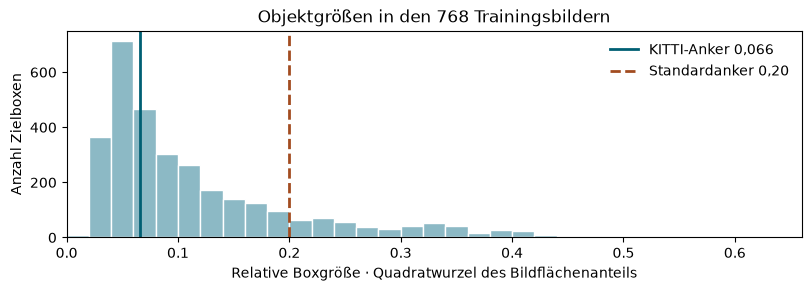

In [2]:
box_scales = []
for image_id in ids["train"]:
    with Image.open(image_path(image_id)) as photo:
        width, height = photo.size
    for _, (left, top, right, bottom) in annotations(image_id, width, height):
        relative_area = (right - left) * (bottom - top) / (width * height)
        box_scales.append(np.sqrt(relative_area))

fig, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
ax.hist(box_scales, bins=np.arange(0, 0.70, 0.02), color="#8cb9c5", edgecolor="white")
ax.axvline(0.066, color="#005f73", lw=2, label="KITTI-Anker 0,066")
ax.axvline(0.20, color="#a24c20", lw=2, ls="--", label="Standardanker 0,20")
ax.set(xlim=(0, 0.66), xlabel="Relative Boxgröße · Quadratwurzel des Bildflächenanteils",
       ylabel="Anzahl Zielboxen", title="Objektgrößen in den 768 Trainingsbildern")
ax.legend(frameon=False)
plt.show()

Bei rund **85 % der 3.131 Trainingsboxen** liegt die relative Boxgröße unter 0,20. Das erklärt die Wahl eines kleineren Startankers. Wie gut ein Anker passt, hängt zusätzlich von Position und Seitenverhältnis ab.

## Woran wir den Detektor messen

**mAP@[0,50:0,95]** gewichtet alle vier Klassen gleich und berücksichtigt zehn Anforderungen an die Boxgenauigkeit. Die *Intersection over Union* (IoU) ist die Schnittfläche zweier Boxen geteilt durch ihre Vereinigungsfläche. AP50 verlangt mindestens 50 % Überlappung nach diesem Maß, AP75 mindestens 75 %. Die AP fasst Präzision und Recall über die nach Konfidenz sortierten Vorhersagen zusammen.

Wir werten alle Schwierigkeitsgrade mit 101 Recall-Stufen und höchstens 100 Vorhersagen je Bild aus. DontCare-Flächen gelten als Ignorierbereiche. Der offizielle KITTI-Benchmark verwendet klassenspezifische IoU-Schwellen, Schwierigkeitsgrade und 40 Recall-Stufen. [KITTI-Auswertungsprotokoll](https://www.cvlibs.net/datasets/kitti/eval_object.php)

## Referenz mit 40 Bildern

Die Referenz trainiert drei Epochen mit Zufallsgewichten, quadratischer Eingabe und Standardankern. Ihre 40 Bilder stammen aus den Trainingsfahrten des größeren Versuchs. So bleibt der Abschlusstest für beide Modelle gleich.

In [3]:
def train_epoch(model, loader, optimizer):
    model.train()
    # Die laufenden Statistiken eingefrorener Backbone-Schichten bleiben ebenfalls fix.
    for layer in model.backbone.modules():
        if isinstance(layer, torch.nn.BatchNorm2d) and not layer.weight.requires_grad:
            layer.eval()
    total = 0.0
    for batch in loader:
        images, targets = zip(*batch)
        targets = [{"boxes": t["boxes"][~t["iscrowd"]], "labels": t["labels"][~t["iscrowd"]]}
                   for t in targets]
        optimizer.zero_grad(set_to_none=True)
        loss = sum(model(list(images), targets).values())
        if not loss.isfinite():
            raise ValueError("Der Trainingsverlust ist nicht endlich.")
        loss.backward()
        optimizer.step()
        total += loss.item() * len(batch)
    return total / len(loader.dataset)

baseline = ssdlite320_mobilenet_v3_large(weights=None, weights_backbone=None,
                                         num_classes=len(CLASSES) + 1, detections_per_img=100)
reference_loader = batches(Scenes(ids["train"][:40]), shuffle=True)
reference_optimizer = torch.optim.AdamW(baseline.parameters(), lr=0.001, weight_decay=0.0001)
for epoch in range(3):
    train_epoch(baseline, reference_loader, reference_optimizer)

## Training mit 768 Bildern

Frühe MobileNet-Schichten behalten ihre ImageNet-Gewichte. Die letzten beiden Backbone-Stufen und der Detektionskopf lernen auf KITTI. Die Augmentation erhöht die Vielfalt der Trainingsansichten. AdamW begrenzt die Gewichte durch Weight Decay. Nach jeder Epoche speichern wir bei verbesserter Validierungs-mAP den Checkpoint. Drei Epochen ohne Verbesserung lösen Early Stopping aus.

In [4]:
torch.manual_seed(seed)
model = ssdlite320_mobilenet_v3_large(
    weights=None, weights_backbone=MobileNet_V3_Large_Weights.IMAGENET1K_V1,
    trainable_backbone_layers=2, num_classes=len(CLASSES) + 1, detections_per_img=100,
    image_mean=[0.485, 0.456, 0.406], image_std=[0.229, 0.224, 0.225],
)
model.transform.fixed_size = SIZE
scales = [0.066, 0.13, 0.24, 0.40, 0.60, 0.85, 1.0]
model.anchor_generator = DefaultBoxGenerator([[2, 3] for _ in range(6)], scales=scales)
optimizer = torch.optim.AdamW([
    {"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": 0.0005},
    {"params": model.head.parameters(), "lr": 0.0015},
], weight_decay=0.0005)
loader = batches(train, shuffle=True)
history = []
best_map = -1.0
for epoch in range(1, 13):
    loss = train_epoch(model, loader, optimizer)
    scores, _ = evaluate(model, valid)
    history.append({"Epoche": epoch, "Trainingsverlust": loss, **scores})
    pd.DataFrame(history).to_csv(output / "validation.csv", index=False)
    if scores["mAP"] > best_map:
        best_map, best_epoch = scores["mAP"], epoch
        state = {"model": model.state_dict(), "classes": CLASSES, "size": SIZE, "scales": scales,
                 "epoch": epoch, "val_map": best_map, "split_sha256": hashlib.sha256(manifest.read_bytes()).hexdigest()}
        temporary = checkpoint.with_suffix(".tmp")
        torch.save(state, temporary)
        temporary.replace(checkpoint)
    print(f"Epoche {epoch:2d}   Verlust {loss:.3f}   Validierungs-mAP {scores['mAP']:.4f}")
    if epoch - best_epoch >= 3:
        break

Epoche  1   Verlust 6.732   Validierungs-mAP 0.0166


Epoche  2   Verlust 4.568   Validierungs-mAP 0.0475


Epoche  3   Verlust 3.964   Validierungs-mAP 0.0703


Epoche  4   Verlust 3.491   Validierungs-mAP 0.0719


Epoche  5   Verlust 3.204   Validierungs-mAP 0.0744


Epoche  6   Verlust 2.869   Validierungs-mAP 0.0932


Epoche  7   Verlust 2.588   Validierungs-mAP 0.0753


Epoche  8   Verlust 2.375   Validierungs-mAP 0.0714


Epoche  9   Verlust 2.243   Validierungs-mAP 0.0723


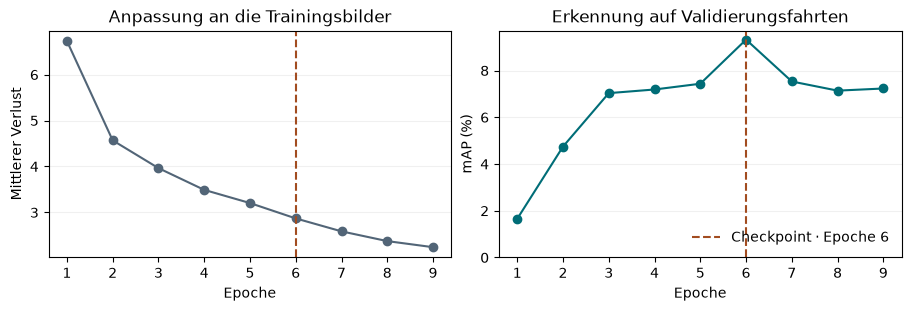

In [5]:
results = pd.DataFrame(history).set_index("Epoche")
fig, (loss_ax, ap_ax) = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
loss_ax.plot(results.index, results.Trainingsverlust, color="#526577", marker="o")
loss_ax.set(ylabel="Mittlerer Verlust", title="Anpassung an die Trainingsbilder")
ap_ax.plot(results.index, results.mAP * 100, color="#006d77", marker="o")
ap_ax.set(ylabel="mAP (%)", title="Erkennung auf Validierungsfahrten", ylim=(0, None))
for ax in (loss_ax, ap_ax):
    ax.axvline(best_epoch, color="#a24c20", ls="--", label=f"Checkpoint · Epoche {best_epoch}")
    ax.set(xlabel="Epoche", xticks=results.index)
    ax.grid(axis="y", alpha=0.18)
ap_ax.legend(frameon=False, loc="lower right")
plt.show()

**Modellwahl.** Nach Epoche 6 sinkt der Trainingsverlust von 2,87 auf 2,24. Gleichzeitig fällt die Validierungs-mAP von 9,32 % auf 7,23 %. Deshalb verwenden wir für neue Fahrten den früheren Checkpoint.

## Abschlusstest auf 24 zurückgehaltenen Fahrten

Nach der Modellwahl laden wir den besten Checkpoint und vergleichen beide Detektoren auf denselben 256 Bildern. Die Tabelle gibt AP-Werte in Prozent an. Die Differenz ist in Prozentpunkten angegeben.

In [6]:
saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
model.load_state_dict(saved["model"])
holdout = Scenes(ids["holdout"])
old_scores, _ = evaluate(baseline, holdout)
new_scores, support = evaluate(model, holdout)
comparison = pd.DataFrame({"Referenz (40 Bilder)": old_scores, "CNN (768 Bilder)": new_scores})
comparison["Differenz"] = comparison.iloc[:, 1] - comparison.iloc[:, 0]
display((100 * comparison.loc[["mAP", "AP50", "AP75"]]).round(2))
per_class = comparison.loc[list(CLASSES)].copy()
per_class["Zielboxen"] = support

,Referenz (40 Bilder),CNN (768 Bilder),Differenz
mAP,0.00,6.39,6.39
AP50,0.01,20.40,20.39
AP75,0.00,2.06,2.06


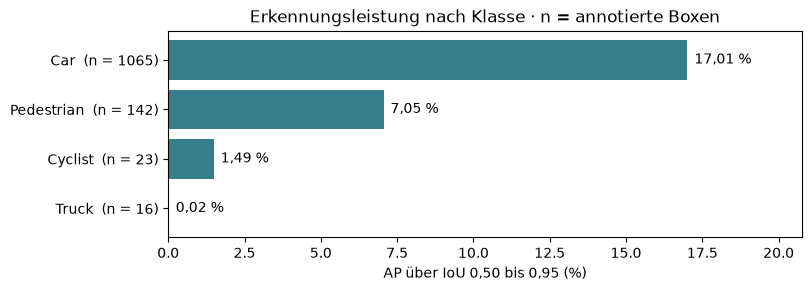

In [7]:
ordered = per_class.sort_values("CNN (768 Bilder)")
labels = [f"{name}  (n = {int(count)})" for name, count in ordered.Zielboxen.items()]
fig, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
bars = ax.barh(labels, ordered["CNN (768 Bilder)"] * 100, color="#367e89")
ax.bar_label(bars, labels=[f"{v:.2f} %".replace(".", ",") for v in bars.datavalues], padding=5)
ax.set(xlabel="AP über IoU 0,50 bis 0,95 (%)", title="Erkennungsleistung nach Klasse · n = annotierte Boxen")
ax.set_xlim(0, max(bars.datavalues) * 1.22)
plt.show()

**Einordnung.** Auf neuen Fahrten steigt die mAP von gerundet 0,00 % auf **6,39 %**. Der Abstand zwischen AP50 (20,40 %) und AP75 (2,06 %) zeigt, wie viel Leistung bei strengerer Lokalisierung verloren geht. Autos erzielen die höchste Klassen-AP. Bei Lkw ist sie fast null, und nur 16 annotierte Boxen machen den Wert besonders empfindlich gegenüber einzelnen Treffern. Der Vergleich erfasst Datenmenge, Vortraining und Modellanpassungen gemeinsam.

## Wie die Boxen im Straßenbild aussehen

Wir zeigen das erste Bild der festen Abschlussliste. Oben stehen die annotierten Objekte, unten die Vorhersagen aus Epoche 6. Die Anzeigeschwelle von 0,25 gilt nur für diese Abbildung. Die AP-Auswertung berücksichtigt auch niedrigere Konfidenzen.

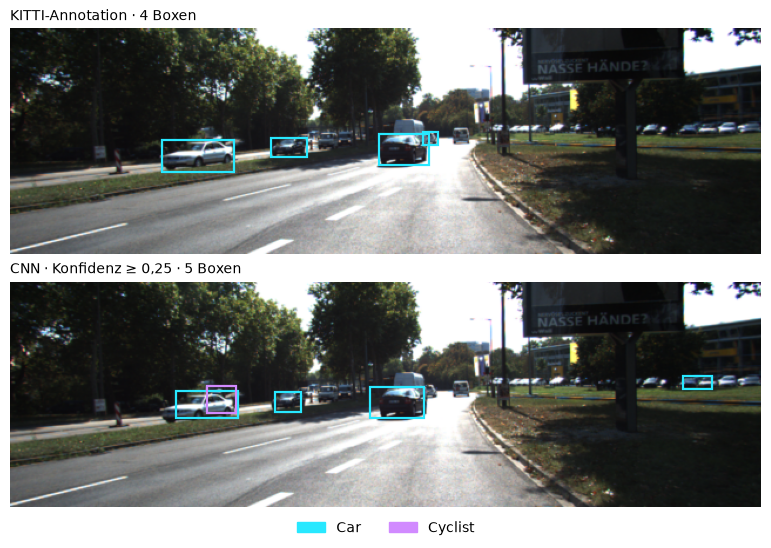

In [8]:
image, target = holdout[0]
with torch.inference_mode():
    prediction = model.eval()([image])[0]
show_boxes = prediction["scores"] >= 0.25
known = ~target["iscrowd"]
panels = [
    ("KITTI-Annotation", target["boxes"][known], target["labels"][known]),
    ("CNN · Konfidenz ≥ 0,25", prediction["boxes"][show_boxes], prediction["labels"][show_boxes]),
]
colors = dict(zip(CLASSES, ["#28e8ff", "#ffb000", "#d18aff", "#a8ff43"]))
fig, axes = plt.subplots(2, 1, figsize=(8, 5.4), layout="constrained")
for ax, (title, boxes, labels) in zip(axes, panels):
    ax.imshow(image.permute(1, 2, 0))
    for (x1, y1, x2, y2), label in zip(boxes.tolist(), labels.tolist()):
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                               edgecolor=colors[CLASSES[label - 1]], lw=1.6))
    ax.set_title(f"{title} · {len(boxes)} Boxen", loc="left", fontsize=10)
    ax.set_axis_off()
shown_classes = sorted({idx for _, _, labels in panels for idx in labels.tolist()})
fig.legend(handles=[Rectangle((0, 0), 1, 1, color=colors[CLASSES[i - 1]], label=CLASSES[i - 1])
                    for i in shown_classes], loc="outside lower center", ncols=4, frameon=False)
plt.show()

Im Beispiel sind vier Autos annotiert. Das CNN legt fünf Boxen über das Bild. Am linken Auto überlagert eine zusätzliche violette Vorhersage für *Cyclist* die Autobox. Das zeigt einen konkreten Klassenfehler, den die Gesamt-mAP allein nicht erkennen lässt.